## Bradley Terry Model

### Maximum Likelihood estimation of Bradley Terry Model
For n=2000, via I-LSR Algorithm and via gradient descent (from scratch)

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import choix
np.random.seed(42) 
import pandas as pd

In [43]:
items = ["Car", "Taxi", "Bike", "Bus", "Walking"]
n_items = len(items)
true_weights = np.array([0.40, 0.25, 0.15, 0.12, 0.08]) # weights taken same as the notes..
true_params = np.log(true_weights)

In [44]:
true_params = true_params - np.mean(true_params)
print("Items:       ", items)
print("True weights:", true_weights)
print("True params: ", np.round(true_params, 3))

Items:        ['Car', 'Taxi', 'Bike', 'Bus', 'Walking']
True weights: [0.4  0.25 0.15 0.12 0.08]
True params:  [ 0.853  0.383 -0.128 -0.351 -0.757]


In [ ]:
n_comparisons = 2000
data = []
for _ in range(n_comparisons):
    i, j = np.random.choice(n_items, size=2, replace=False)
    prob_i_wins = np.exp(true_params[i]) / (np.exp(true_params[i]) + np.exp(true_params[j]))
    if np.random.rand() < prob_i_wins:
        data.append((i, j))   # i wins, j loses
    else:
        data.append((j, i))   # j wins, i loses
print(f"Generated {len(data)} pairwise comparisons")
print(f"First 5 comparisons (winner_idx, loser_idx): {data[:5]}")
print(f"Example decoded: '{items[data[0][0]]}' beat '{items[data[0][1]]}'")

Generated 2000 pairwise comparisons
First 5 comparisons (winner_idx, loser_idx): [(4, 1), (3, 0), (4, 1), (3, 4), (4, 2)]
Example decoded: 'Walking' beat 'Taxi'


In [ ]:
data_arr = np.array(data)
wins = np.bincount(data_arr[:, 0], minlength=n_items)
appearances = np.bincount(data_arr.flatten(), minlength=n_items)
win_rate = wins / appearances
print(f"{'Item':<10}{'Wins':>6}{'Appearances':>14}{'Win Rate':>12}{'True Weight':>14}")
print("-" * 56)
for idx, name in enumerate(items):
    print(f"{name:<10}{wins[idx]:>6}{appearances[idx]:>14}"
          f"{win_rate[idx]:>12.3f}{true_weights[idx]:>14.3f}")

Item        Wins   Appearances    Win Rate   True Weight
--------------------------------------------------------
Car          592           811       0.730         0.400
Taxi         513           810       0.633         0.250
Bike         372           810       0.459         0.150
Bus          293           773       0.379         0.120
Walking      230           796       0.289         0.080


Now, fitting the bradley terry via mle using choix..
choix.ilsr_pairwise runs the I-LSR algorithm (Iterative Luce Spectral Ranking)


In [ ]:
estimated_params = choix.ilsr_pairwise(
    n_items=n_items,
    data=data,
    alpha=0.01   
)

print("True parameters:     ", np.round(true_params, 3))
print("Estimated parameters:", np.round(estimated_params, 3))
print()
print(f"Sum of estimated params: {estimated_params.sum():.6f}   (should be ~0)")

True parameters:      [ 0.853  0.383 -0.128 -0.351 -0.757]
Estimated parameters: [ 0.827  0.461 -0.122 -0.418 -0.749]

Sum of estimated params: -0.000000   (should be ~0)


Now, visualizing the true v/s estimated paramteters

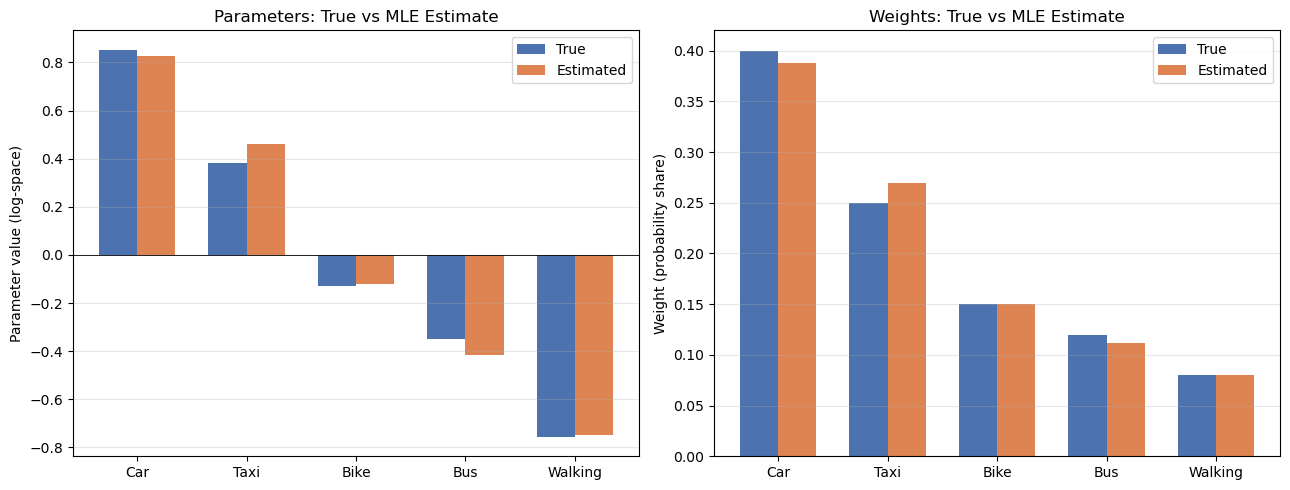

Mean absolute error on parameters: 0.0370
Mean absolute error on weights:    0.0080


In [39]:
estimated_weights = np.exp(estimated_params)
estimated_weights = estimated_weights / estimated_weights.sum()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(n_items)
bar_width = 0.35
axes[0].bar(x - bar_width/2, true_params,      bar_width, label="True",      color="#4C72B0")
axes[0].bar(x + bar_width/2, estimated_params, bar_width, label="Estimated", color="#DD8452")
axes[0].axhline(0, color="black", linewidth=0.6)
axes[0].set_xticks(x)
axes[0].set_xticklabels(items)
axes[0].set_ylabel("Parameter value (log-space)")
axes[0].set_title("Parameters: True vs MLE Estimate")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)
axes[1].bar(x - bar_width/2, true_weights,      bar_width, label="True",      color="#4C72B0")
axes[1].bar(x + bar_width/2, estimated_weights, bar_width, label="Estimated", color="#DD8452")
axes[1].set_xticks(x)
axes[1].set_xticklabels(items)
axes[1].set_ylabel("Weight (probability share)")
axes[1].set_title("Weights: True vs MLE Estimate")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
param_mae  = np.mean(np.abs(true_params  - estimated_params))
weight_mae = np.mean(np.abs(true_weights - estimated_weights))
print(f"Mean absolute error on parameters: {param_mae:.4f}")
print(f"Mean absolute error on weights:    {weight_mae:.4f}")

Here, bradley terry via gradient descent

True parameters:            [ 0.853  0.383 -0.128 -0.351 -0.757]
choix I-LSR:                [ 0.827  0.461 -0.122 -0.418 -0.749]
Gradient descent (scratch): [ 0.827  0.461 -0.122 -0.418 -0.749]

Mean absolute error (GD vs true):  0.03695
Mean Absolute error (GD vs choix): 0.00014


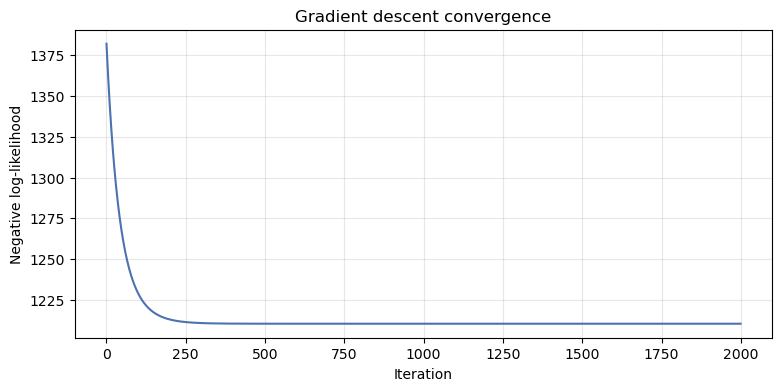

In [47]:
data_arr = np.array(data)
winners = data_arr[:, 0]   
losers  = data_arr[:, 1]   
def sigmoid(x):
    """Numerically stable sigmoid never overflows for large |x|."""
    return np.where(x >= 0,
                    1.0 / (1.0 + np.exp(-x)),
                    np.exp(x) / (1.0 + np.exp(x)))
def neg_log_likelihood(params):
    """Negative log-likelihood of the Bradley-Terry model.
    We minimize this = maximize log-likelihood."""
    diff = params[winners] - params[losers]      
    return np.sum(np.log1p(np.exp(-diff)))        
def gradient_of_nll(params):
    p_winner_wins = sigmoid(params[winners] - params[losers])
    residual = 1.0 - p_winner_wins    
    grad = np.zeros(n_items)
    np.add.at(grad, winners, -residual)
    np.add.at(grad, losers,   residual)
    return grad / len(winners)      
params_gd     = np.zeros(n_items)   
learning_rate = 0.1
n_iterations  = 2000
nll_history = []
for step in range(n_iterations):
    g = gradient_of_nll(params_gd)
    params_gd = params_gd - learning_rate * g
    params_gd = params_gd - np.mean(params_gd)
    nll_history.append(neg_log_likelihood(params_gd))
print(f"True parameters:            {np.round(true_params,      3)}")
print(f"choix I-LSR:                {np.round(estimated_params, 3)}")
print(f"Gradient descent (scratch): {np.round(params_gd,        3)}")
print()
print(f"Mean absolute error (GD vs true):  {np.mean(np.abs(params_gd - true_params)):.5f}")
print(f"Mean Absolute error (GD vs choix): {np.mean(np.abs(params_gd - estimated_params)):.5f}")
plt.figure(figsize=(9, 4))
plt.plot(nll_history, color="#4C72B0")
plt.xlabel("Iteration")
plt.ylabel("Negative log-likelihood")
plt.title("Gradient descent convergence")
plt.grid(alpha=0.3)
plt.show()

n =     50:  MAE = 0.3469  ± 0.1354
n =    100:  MAE = 0.2257  ± 0.1176
n =    200:  MAE = 0.1729  ± 0.0611
n =    500:  MAE = 0.1101  ± 0.0483
n =   1000:  MAE = 0.0743  ± 0.0310
n =   2000:  MAE = 0.0452  ± 0.0163
n =   5000:  MAE = 0.0380  ± 0.0127
n =  10000:  MAE = 0.0230  ± 0.0068
n =  20000:  MAE = 0.0147  ± 0.0049
n =  50000:  MAE = 0.0103  ± 0.0039


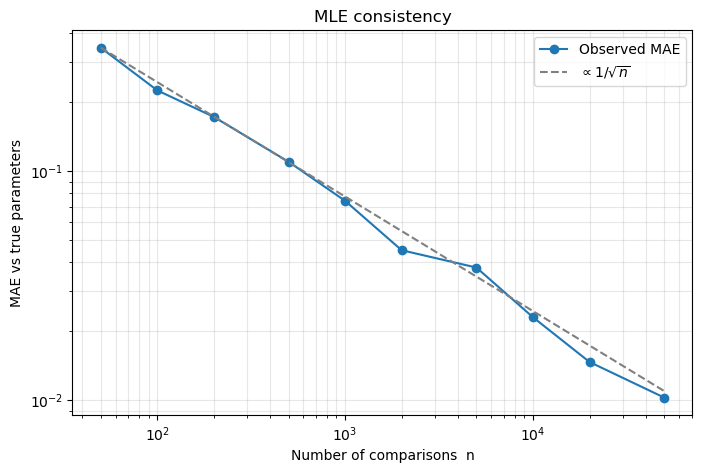

In [52]:
n_values = [50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000, 50000]
n_seeds  = 20   

def simulate_data(n_comparisons, rng):
    a = rng.integers(0, n_items, size=n_comparisons)
    b = (a + rng.integers(1, n_items, size=n_comparisons)) % n_items
    pa, pb = np.exp(true_params[a]), np.exp(true_params[b])
    a_wins = rng.random(n_comparisons) < pa / (pa + pb)
    winners = np.where(a_wins, a, b)
    losers  = np.where(a_wins, b, a)
    return np.column_stack([winners, losers])

mae_means, mae_stds = [], []
for n in n_values:
    maes = []
    for s in range(n_seeds):
        rng  = np.random.default_rng(s)          
        data = simulate_data(n, rng)
        est  = choix.ilsr_pairwise(n_items=n_items, data=data, alpha=0.01)
        est  = est - est.mean()                  
        maes.append(np.mean(np.abs(est - true_params)))
    mae_means.append(np.mean(maes))
    mae_stds.append(np.std(maes))
    print(f"n = {n:>6}:  MAE = {mae_means[-1]:.4f}  ± {mae_stds[-1]:.4f}")

mae_means = np.array(mae_means)

plt.figure(figsize=(8, 5))
plt.loglog(n_values, mae_means, "o-", label="Observed MAE")
ref = mae_means[0] * np.sqrt(n_values[0]) / np.sqrt(n_values)  # 1/sqrt(n) reference
plt.loglog(n_values, ref, "--", color="gray", label=r"$\propto 1/\sqrt{n}$")
plt.xlabel("Number of comparisons  n")
plt.ylabel("MAE vs true parameters")
plt.title("MLE consistency")
plt.legend(); plt.grid(True, which="both", alpha=0.3)
plt.show()

n =               50:  MAE = 0.355689
n =              100:  MAE = 0.255530
n =              200:  MAE = 0.172178
n =              500:  MAE = 0.104794
n =             1000:  MAE = 0.075188
n =             2000:  MAE = 0.049733
n =             5000:  MAE = 0.029766
n =            10000:  MAE = 0.020624
n =            20000:  MAE = 0.015463
n =            50000:  MAE = 0.010011
n =           100000:  MAE = 0.006565
n =          1000000:  MAE = 0.002222
n =         10000000:  MAE = 0.000718
n =        100000000:  MAE = 0.000222
n =       1000000000:  MAE = 0.000070
n =      10000000000:  MAE = 0.000022
n =     100000000000:  MAE = 0.000007
n =    1000000000000:  MAE = 0.000002

Fitted log-log slope: -0.503   (theory predicts about -0.5)


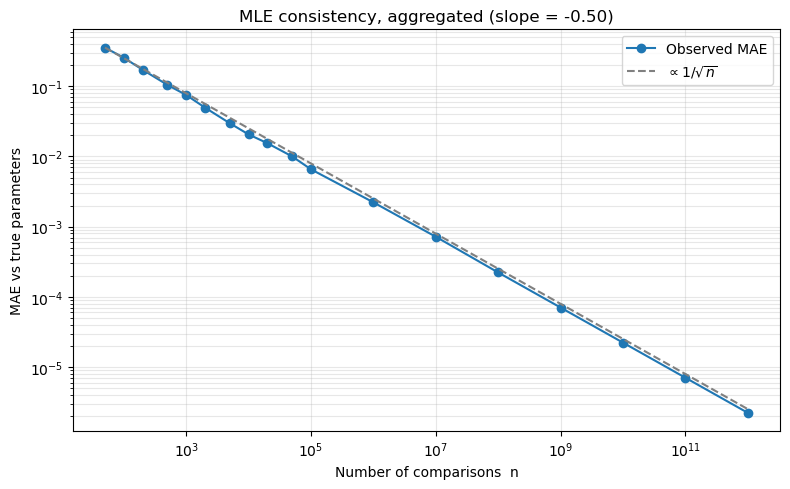

In [53]:
pairs   = [(i, j) for i in range(n_items) for j in range(i + 1, n_items)]
n_pairs = len(pairs)

def simulate_countmat(n, rng):
    counts = rng.multinomial(n, [1.0 / n_pairs] * n_pairs)
    W = np.zeros((n_items, n_items))
    for (i, j), m in zip(pairs, counts):
        p_i = np.exp(true_params[i]) / (np.exp(true_params[i]) + np.exp(true_params[j]))
        wins_i = rng.binomial(m, p_i)          
        W[i, j] += wins_i
        W[j, i] += m - wins_i
    return W

n_values = [50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000, 50000,
            10**5, 10**6, 10**7, 10**8, 10**9, 10**10, 10**11, 10**12]
n_seeds  = 20

mae_means = []
for n in n_values:
    maes = []
    for s in range(n_seeds):
        rng = np.random.default_rng(s)
        W   = simulate_countmat(n, rng)
        est = choix.ilsr_pairwise_dense(W, alpha=0.01)
        est = est - est.mean()
        maes.append(np.mean(np.abs(est - true_params)))
    mae_means.append(np.mean(maes))
    print(f"n = {n:>16}:  MAE = {mae_means[-1]:.6f}")

mae_means = np.array(mae_means)
n_values  = np.array(n_values, dtype=float)

slope, _ = np.polyfit(np.log(n_values), np.log(mae_means), 1)
print(f"\nFitted log-log slope: {slope:.3f}   (theory predicts about -0.5)")

plt.figure(figsize=(8, 5))
plt.loglog(n_values, mae_means, "o-", label="Observed MAE")
ref = mae_means[0] * np.sqrt(n_values[0]) / np.sqrt(n_values)
plt.loglog(n_values, ref, "--", color="gray", label=r"$\propto 1/\sqrt{n}$")
plt.xlabel("Number of comparisons  n")
plt.ylabel("MAE vs true parameters")
plt.title(f"MLE consistency, aggregated (slope = {slope:.2f})")
plt.legend(); plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()